In [2]:
import scanpy as sc

adata = sc.read_h5ad('/home/data/t180330/Visium_human_breast_cancer/deconvolution_models/sp.h5ad')
adata.obs[adata_vis.uns['mod']['factor_names']] = adata_vis.obsm['q05_cell_abundance_w_sf']

In [3]:
adata.obs

,nCount_RNA,nFeature_RNA,patientid,subtype,Classification,sample_id,in_tissue,array_row,array_col,n_genes,...,Bn.TCL1A,Bmem,B.plasma.IgA,B.plasma.IgG,B.cycling,Endo.ACKR1,Endo.RGCC,Endo.LYVE1,Peri.RGS5,pDC.LILRA4
TACCGATCCAACACTT-1-human_bc_spatial_1142243F,4073.0,2071.0,1142243F,TNBC,Artefact,human_bc_spatial_1142243F,NaN,NaN,NaN,NaN,...,0.022497,0.020193,0.037475,0.018498,0.020019,0.011983,0.009109,0.014215,0.019473,0.009101
GATAAGGGACGATTAG-1-human_bc_spatial_1142243F,4628.0,2320.0,1142243F,TNBC,Artefact,human_bc_spatial_1142243F,NaN,NaN,NaN,NaN,...,0.016061,0.019979,0.095420,0.032412,0.016224,0.008209,0.034733,0.011401,0.010949,0.006740
TGTTGGCTGGCGGAAG-1-human_bc_spatial_1142243F,5116.0,2494.0,1142243F,TNBC,Artefact,human_bc_spatial_1142243F,NaN,NaN,NaN,NaN,...,0.016862,0.015967,0.074918,0.023124,0.016222,0.007795,0.025165,0.007139,0.105439,0.008383
GCGAGGGACTGCTAGA-1-human_bc_spatial_1142243F,8170.0,3464.0,1142243F,TNBC,Artefact,human_bc_spatial_1142243F,NaN,NaN,NaN,NaN,...,0.057609,0.056430,0.107111,0.061022,0.049856,0.021872,0.041612,0.009397,0.026771,0.024351
GCGCGTTTAAATCGTA-1-human_bc_spatial_1142243F,7534.0,3345.0,1142243F,TNBC,Artefact,human_bc_spatial_1142243F,NaN,NaN,NaN,NaN,...,0.057001,0.053200,0.216506,0.042934,0.065179,0.014382,0.014198,0.012688,0.126112,0.019982
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTGTTCAGTGTGCTAC-1-human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,NaN,NaN,NaN,NaN,NaN,human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,1.0,24.0,64.0,4077.0,...,0.011404,0.011356,0.146501,0.028610,0.009969,0.010151,0.003613,0.001763,0.005502,0.009959
TTGTTGTGTGTCAAGA-1-human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,NaN,NaN,NaN,NaN,NaN,human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,1.0,31.0,77.0,5635.0,...,0.058963,0.031354,0.163873,0.050475,0.046119,0.215427,0.007760,0.119453,0.034399,0.124942
TTGTTTCACATCCAGG-1-human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,NaN,NaN,NaN,NaN,NaN,human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,1.0,58.0,42.0,1912.0,...,0.002569,0.004318,0.004818,0.033988,0.001998,0.003760,0.000944,0.000659,0.001704,0.000826
TTGTTTCATTAGTCTA-1-human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,NaN,NaN,NaN,NaN,NaN,human_bc_spatial_Visium_FFPE_Human_Breast_Cancer,1.0,60.0,30.0,3892.0,...,0.031907,0.020206,0.032843,0.013656,0.012302,0.451674,0.003321,0.001200,0.073877,0.007391


In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr


def add_subtype_to_adata(
    adata,
    sample_subtype_map,
    sample_col='sample_id',
    subtype_col='subtype'
):
    """
    Add subtype annotation to adata.obs by sample-to-subtype mapping.

    Parameters
    ----------
    adata : AnnData
    sample_subtype_map : dict
        {sample_id: subtype}.
    sample_col : str
        Column in adata.obs containing sample IDs.
    subtype_col : str
        Output column name for subtype.

    Returns
    -------
    AnnData
    """
    mapping_series = pd.Series(sample_subtype_map)
    adata.obs[subtype_col] = adata.obs[sample_col].map(mapping_series)

    missing = adata.obs[subtype_col].isna().sum()
    if missing > 0:
        missing_samples = adata.obs.loc[adata.obs[subtype_col].isna(), sample_col].unique()
        print(f"Warning: {missing} spots from samples {list(missing_samples)} "
              "have no subtype mapping")

    # Convert to ordered categorical
    subtype_order = sorted(set(sample_subtype_map.values()))
    adata.obs[subtype_col] = pd.Categorical(
        adata.obs[subtype_col], categories=subtype_order, ordered=True
    )

    print(f"Added '{subtype_col}' for {adata.obs[sample_col].nunique()} samples")
    print(adata.obs.groupby([sample_col, subtype_col], observed=False).size().groupby(level=0).first())
    return adata


def compute_pairwise_colocalization(
    adata,
    celltype_matrix,
    sample_col='sample_id',
    subtype_col='subtype',
    pairs=None,
    min_spots=10
):
    """
    Compute per-sample Pearson correlation for selected cell-type pairs.

    Parameters
    ----------
    adata : AnnData
        Spatial object with .obs containing sample_col and subtype_col.
    celltype_matrix : np.ndarray or pd.DataFrame
        Spots x cell types abundance matrix. If DataFrame, columns are cell types.
    sample_col : str
        Column in adata.obs for sample ID.
    subtype_col : str
        Column in adata.obs for subtype (e.g., Basal, HER2, LumA, LumB).
    pairs : list of tuples
        Cell-type pairs to test, e.g., [('CD8-T', 'cDC'), ('B_cell', 'Tfh')].
        If None, all pairs are computed.
    min_spots : int
        Minimum spots required in a sample to compute correlation.

    Returns
    -------
    pd.DataFrame
        Columns: sample, subtype, celltype_a, celltype_b, r, pvalue, pair
    """
    if isinstance(celltype_matrix, pd.DataFrame):
        ct_names = list(celltype_matrix.columns)
        mat = celltype_matrix.values
    else:
        ct_names = [f"CT{i}" for i in range(celltype_matrix.shape[1])]
        mat = np.asarray(celltype_matrix)

    print(f"Available cell types in matrix: {ct_names[:10]}{'...' if len(ct_names) > 10 else ''}")

    if pairs is None:
        pairs = [(ct_names[i], ct_names[j])
                 for i in range(len(ct_names))
                 for j in range(i + 1, len(ct_names))]
    else:
        # Check requested pairs exist
        requested = set([g for p in pairs for g in p])
        missing = requested - set(ct_names)
        if missing:
            print(f"WARNING: these cell types are NOT in the matrix: {missing}")
            print(f"Available names include: {ct_names[:20]}")

    obs = adata.obs.copy()
    obs['_ct_index'] = np.arange(len(obs))

    # Drop samples with NaN subtype
    na_samples = obs[obs[subtype_col].isna()][sample_col].unique()
    if len(na_samples) > 0:
        print(f"Dropping {len(na_samples)} sample(s) with missing subtype: {list(na_samples)}")
        obs = obs[~obs[sample_col].isin(na_samples)].copy()

    results = []
    for sample in obs[sample_col].unique():
        mask = obs[sample_col] == sample
        if mask.sum() < min_spots:
            continue
        subtype = obs.loc[mask, subtype_col].iloc[0]
        idx = obs.loc[mask, '_ct_index'].values
        sub_mat = mat[idx, :]

        for a, b in pairs:
            if a not in ct_names or b not in ct_names:
                continue
            i = ct_names.index(a)
            j = ct_names.index(b)
            x = sub_mat[:, i]
            y = sub_mat[:, j]

            # Skip if no variance
            if np.std(x) == 0 or np.std(y) == 0:
                continue

            r, p = pearsonr(x, y)
            results.append({
                'sample': sample,
                'subtype': subtype,
                'celltype_a': a,
                'celltype_b': b,
                'r': r,
                'pvalue': p,
                'pair': f"{a} — {b}",
                'n_spots': mask.sum()
            })

    return pd.DataFrame(results)


def plot_colocalization_bars(
    corr_df,
    pairs=None,
    subtype_order=None,
    palette=None,
    figsize=None,
    layout='horizontal',
    clean_names=True,
    save_path=None,
    title='Cell-type co-localization (Pearson r)'
):
    """
    Bar chart of positive Pearson correlations per sample and cell-type pair.

    Parameters
    ----------
    corr_df : pd.DataFrame
        Output from compute_pairwise_colocalization().
    pairs : list of tuples, optional
        Subset of pairs to plot.
    subtype_order : list, optional
        Order of subtypes for legend.
    palette : dict, optional
        Color map for subtypes.
    figsize : tuple, optional
        Default: horizontal=(6*n_pairs, 7), vertical=(12, 5*n_pairs).
    layout : str
        'horizontal' (1 x n_pairs) or 'vertical' (n_pairs x 1).
    clean_names : bool
        Remove cell2location prefixes from pair labels.
    save_path : str, optional
    title : str
    """
    df = corr_df.copy()

    if df.empty:
        print("ERROR: corr_df is empty. No correlations were computed.")
        print("Check that cell-type names in 'pairs' match column names in celltype_matrix.")
        return

    if 'r' not in df.columns:
        print(f"ERROR: corr_df has columns {list(df.columns)}, expected 'r'.")
        return

    # Only positive correlations
    df = df[df['r'] > 0].copy()

    if df.empty:
        print("No positive correlations to plot.")
        return

    if pairs is not None:
        pair_names = [f"{a} — {b}" for a, b in pairs]
        df = df[df['pair'].isin(pair_names)].copy()

    if df.empty:
        print("No positive correlations to plot.")
        return

    if subtype_order is None:
        subtype_order = sorted(df['subtype'].unique())

    if palette is None:
        palette = {
            'Basal': '#E64B35',
            'HER2':  '#4DBBD5',
            'LumA':  '#00A087',
            'LumB':  '#3C5488',
            'Normal': '#F39B7F'
        }

    # Order samples by subtype then by mean r across pairs
    sample_order = (df.groupby(['subtype', 'sample'])['r']
                      .mean()
                      .reset_index()
                      .sort_values(['subtype', 'r'], ascending=[True, False])
                      ['sample']
                      .tolist())

    # Clean pair labels
    if clean_names:
        df['pair_clean'] = df['pair'].str.replace(
            r'q05cell_abundance_w_sf_', '', regex=True
        )
    else:
        df['pair_clean'] = df['pair']

    n_pairs = df['pair'].nunique()
    n_samples = df['sample'].nunique()

    if figsize is None:
        if layout == 'horizontal':
            figsize = (max(6 * n_pairs, 2 * n_samples), 7)
        else:
            figsize = (max(14, 1.2 * n_samples), 5 * n_pairs)

    if n_pairs == 1:
        fig, ax = plt.subplots(figsize=figsize)
        axes = [ax]
    elif layout == 'vertical':
        fig, axes = plt.subplots(n_pairs, 1, figsize=figsize, sharex=True)
        axes = [axes] if n_pairs == 1 else list(axes)
    else:
        fig, axes = plt.subplots(1, n_pairs, figsize=figsize, sharey=True)
        axes = [axes] if n_pairs == 1 else list(axes)

    for ax, pair in zip(axes, sorted(df['pair_clean'].unique())):
        sub = df[df['pair_clean'] == pair].copy()
        sub['sample'] = pd.Categorical(sub['sample'], categories=sample_order, ordered=True)
        sub = sub.sort_values('sample')

        sns.barplot(
            data=sub,
            x='sample', y='r', hue='subtype',
            hue_order=subtype_order, palette=palette,
            dodge=False, ax=ax
        )
        ax.axhline(0, color='black', linewidth=0.8)
        ax.set_title(pair, fontsize=13, fontweight='bold')
        ax.set_xlabel('')
        ax.set_ylabel('Pearson r (positive)', fontsize=12)
        ax.set_ylim(0, max(df['r'].max() * 1.15, 0.1))

        if layout == 'vertical':
            ax.tick_params(axis='x', rotation=45, ha='right', labelsize=10)
            ax.legend(title='Subtype', bbox_to_anchor=(1.02, 1), loc='upper left',
                      fontsize=9)
        else:
            ax.tick_params(axis='x', rotation=90, labelsize=9)
            ax.legend(title='Subtype', bbox_to_anchor=(1.02, 1), loc='upper left',
                      fontsize=9)

    fig.suptitle(title, fontsize=15, fontweight='bold', y=1.02)
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved to {save_path}")

    plt.show()


def run_colocalization_analysis(
    adata,
    celltype_matrix,
    pairs,
    sample_col='sample_id',
    subtype_col='subtype',
    min_spots=10,
    save_prefix='coloc'
):
    """
    One-step wrapper: compute correlations and plot bar chart.

    Returns
    -------
    pd.DataFrame
    """
    corr_df = compute_pairwise_colocalization(
        adata, celltype_matrix,
        sample_col=sample_col,
        subtype_col=subtype_col,
        pairs=pairs,
        min_spots=min_spots
    )

    corr_df.to_csv(f"{save_prefix}_correlations.csv", index=False)

    plot_colocalization_bars(
        corr_df,
        pairs=pairs,
        save_path=f"{save_prefix}_barplot.pdf",
        title='Cell-type co-localization across samples'
    )

    return corr_df

In [11]:
import pandas as pd
import numpy as np

Added 'subtype' for 11 samples
sample_id
human_bc_spatial_1142243F                                 0
human_bc_spatial_1160920F                              4895
human_bc_spatial_CID4290                                  0
human_bc_spatial_CID4465                               1211
human_bc_spatial_CID44971                              1162
human_bc_spatial_CID4535                                  0
human_bc_spatial_Parent_Visium_Human_BreastCancer         0
human_bc_spatial_V1_Breast_Cancer_Block_A_Section_1       0
human_bc_spatial_V1_Breast_Cancer_Block_A_Section_2       0
human_bc_spatial_V1_Human_Invasive_Ductal_Carcinoma       0
human_bc_spatial_Visium_FFPE_Human_Breast_Cancer          0
dtype: int64
Available cell types in matrix: ['q05cell_abundance_w_sf_CD4.CCR7', 'q05cell_abundance_w_sf_CD4.FOXP3', 'q05cell_abundance_w_sf_CD4.CXCL13', 'q05cell_abundance_w_sf_CD8.GZMK', 'q05cell_abundance_w_sf_CD8.CCL5', 'q05cell_abundance_w_sf_CD8.CXCL13', 'q05cell_abundance_w_sf_CD8.gdT.TRDC',

/tmp/ipykernel_2964657/2001008093.py:47: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(adata.obs.groupby([sample_col, subtype_col], observed=False).size().groupby(level=0).first())


Saved to coloc_example_barplot.pdf


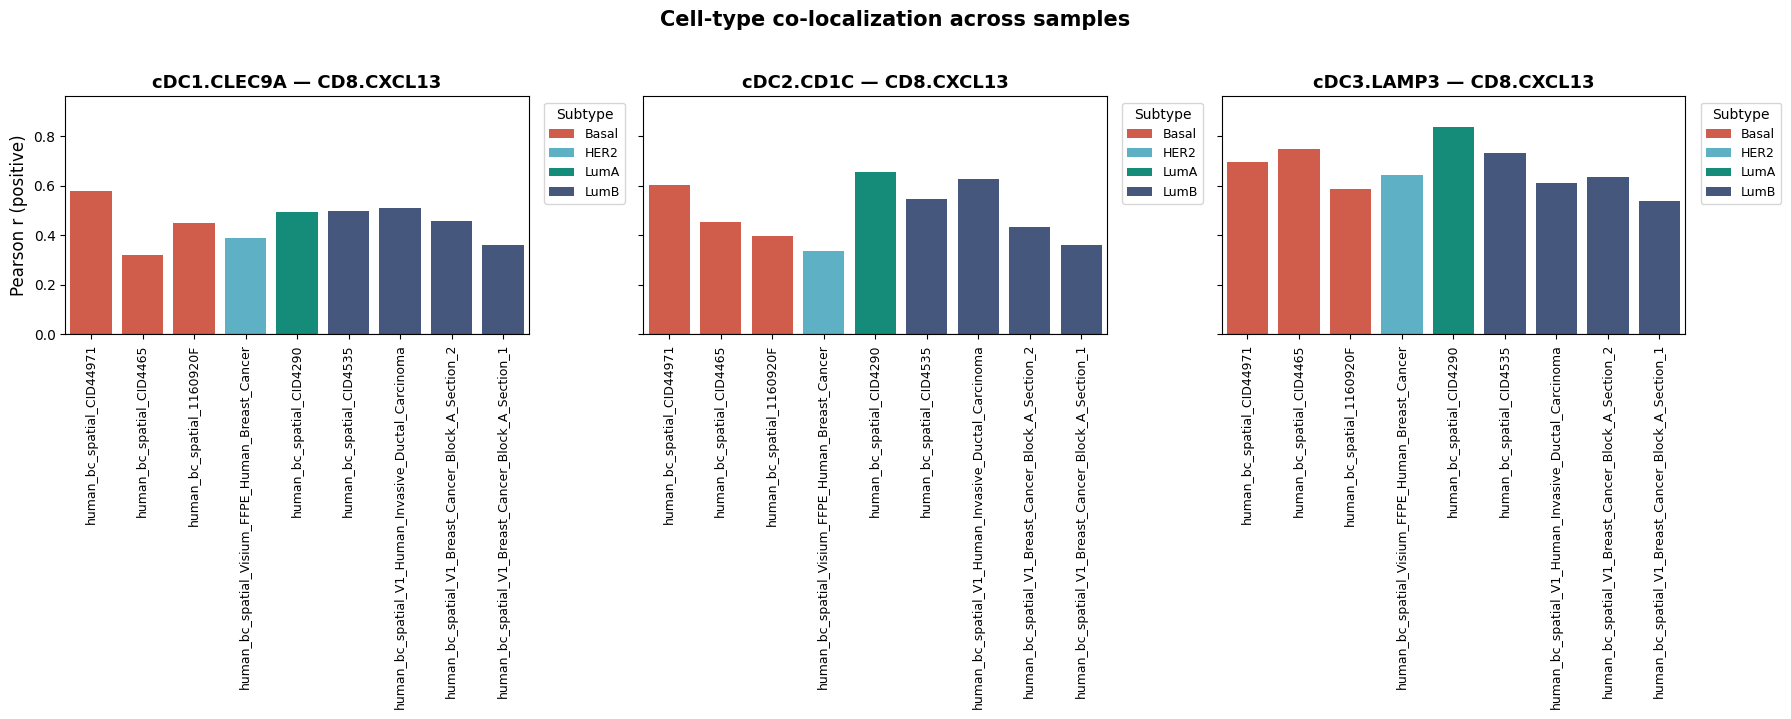

In [20]:
# 1. 定义 sample → subtype 映射
sample_subtype_map = {
    "human_bc_spatial_1160920F": "Basal",
    "human_bc_spatial_CID4465": "Basal",
    "human_bc_spatial_CID44971": "Basal",
    "human_bc_spatial_Visium_FFPE_Human_Breast_Cancer": "HER2",
    "human_bc_spatial_CID4290": "LumA",
    "human_bc_spatial_CID4535": "LumB",
    "human_bc_spatial_V1_Breast_Cancer_Block_A_Section_1": "LumB",
    "human_bc_spatial_V1_Breast_Cancer_Block_A_Section_2": "LumB",
    "human_bc_spatial_V1_Human_Invasive_Ductal_Carcinoma": "LumB"
}

# 2. 加到 adata.obs
adata = add_subtype_to_adata(
    adata,
    sample_subtype_map=sample_subtype_map,
    sample_col='sample_id',
    subtype_col='subtype'
)

# 3. 运行共定位分析
cell2loc = adata.obsm['q05_cell_abundance_w_sf']
cell2loc.columns = [c.replace('q05cell_abundance_wsf_', '') for c in cell2loc.columns]

pairs = [
    ('q05cell_abundance_w_sf_cDC1.CLEC9A', 'q05cell_abundance_w_sf_CD8.CXCL13'),
    ('q05cell_abundance_w_sf_cDC2.CD1C', 'q05cell_abundance_w_sf_CD8.CXCL13'),
    ('q05cell_abundance_w_sf_cDC3.LAMP3', 'q05cell_abundance_w_sf_CD8.CXCL13')
]

corr_df = run_colocalization_analysis(
    adata,
    celltype_matrix=cell2loc,
    pairs=pairs,
    sample_col='sample_id',
    subtype_col='subtype',
    save_prefix='coloc_example'
)

In [ ]:
# ==============================================================================
# Example usage
# ==============================================================================

# # Assume adata has:
# #   adata.obs['sample_id']
# #   adata.obs['subtype']  # Basal / HER2 / LumA / LumB
# #   adata.obsm['q05_cell_abundance_w_sf']  # cell2location output
#
# from colocalization_correlation import run_colocalization_analysis
#
# # Extract cell-type matrix from cell2location
# cell2loc = adata.obsm['q05_cell_abundance_w_sf']
# # Remove suffix if cell2location adds one
# cell2loc.columns = [c.replace('q05cell_abundance_w_sf_', '') for c in cell2loc.columns]
#
# pairs = [
#     ('B_cells', 'T_cd4'),       # example pair 1
#     ('T_cytotoxic', 'cDC'),      # example pair 2
#     ('Macrophages', 'Monocytes') # example pair 3
# ]
#
# corr_df = run_colocalization_analysis(
#     adata,
#     celltype_matrix=cell2loc,
#     pairs=pairs,
#     sample_col='sample_id',
#     subtype_col='subtype',
#     save_prefix='coloc_example'
# )
